In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb


In [31]:
data= pd.read_csv('ipl.csv')

In [32]:
data= pd.DataFrame(data)
data.tail(10)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
179068,11415,2,Chennai Super Kings,Mumbai Indians,19,3,RA Jadeja,SR Watson,JJ Bumrah,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
179069,11415,2,Chennai Super Kings,Mumbai Indians,19,4,RA Jadeja,SR Watson,JJ Bumrah,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
179070,11415,2,Chennai Super Kings,Mumbai Indians,19,5,RA Jadeja,SR Watson,JJ Bumrah,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
179071,11415,2,Chennai Super Kings,Mumbai Indians,19,6,RA Jadeja,SR Watson,JJ Bumrah,0,...,4,0,0,0,4,4,8,NaN,NaN,NaN
179072,11415,2,Chennai Super Kings,Mumbai Indians,20,1,SR Watson,RA Jadeja,SL Malinga,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
179073,11415,2,Chennai Super Kings,Mumbai Indians,20,2,RA Jadeja,SR Watson,SL Malinga,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
179074,11415,2,Chennai Super Kings,Mumbai Indians,20,3,SR Watson,RA Jadeja,SL Malinga,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
179075,11415,2,Chennai Super Kings,Mumbai Indians,20,4,SR Watson,RA Jadeja,SL Malinga,0,...,0,0,0,0,1,0,1,SR Watson,run out,KH Pandya
179076,11415,2,Chennai Super Kings,Mumbai Indians,20,5,SN Thakur,RA Jadeja,SL Malinga,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
179077,11415,2,Chennai Super Kings,Mumbai Indians,20,6,SN Thakur,RA Jadeja,SL Malinga,0,...,0,0,0,0,0,0,0,SN Thakur,lbw,NaN


In [33]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 179078 entries, 0 to 179077
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype
---  ------            --------------   -----
 0   match_id          179078 non-null  int64
 1   inning            179078 non-null  int64
 2   batting_team      179078 non-null  str  
 3   bowling_team      179078 non-null  str  
 4   over              179078 non-null  int64
 5   ball              179078 non-null  int64
 6   batsman           179078 non-null  str  
 7   non_striker       179078 non-null  str  
 8   bowler            179078 non-null  str  
 9   is_super_over     179078 non-null  int64
 10  wide_runs         179078 non-null  int64
 11  bye_runs          179078 non-null  int64
 12  legbye_runs       179078 non-null  int64
 13  noball_runs       179078 non-null  int64
 14  penalty_runs      179078 non-null  int64
 15  batsman_runs      179078 non-null  int64
 16  extra_runs        179078 non-null  int64
 17  total_runs        179

In [34]:
# analyse Chennai Super Kings vs Mumbai Indians match
match= data[((data['batting_team']=='Chennai Super Kings') &(data['bowling_team']=='Mumbai Indians'))|((data['bowling_team']=='Chennai Super Kings') &(data['batting_team']=='Mumbai Indians'))]

In [35]:
match
inning1=match[match['inning']==1]
inning1.head(10)

,match_id,inning,batting_team,bowling_team,over,ball,batsman,non_striker,bowler,is_super_over,...,bye_runs,legbye_runs,noball_runs,penalty_runs,batsman_runs,extra_runs,total_runs,player_dismissed,dismissal_kind,fielder
15486,67,1,Chennai Super Kings,Mumbai Indians,1,1,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,1,1,NaN,NaN,NaN
15487,67,1,Chennai Super Kings,Mumbai Indians,1,2,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15488,67,1,Chennai Super Kings,Mumbai Indians,1,3,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15489,67,1,Chennai Super Kings,Mumbai Indians,1,4,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15490,67,1,Chennai Super Kings,Mumbai Indians,1,5,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,4,0,4,NaN,NaN,NaN
15491,67,1,Chennai Super Kings,Mumbai Indians,1,6,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15492,67,1,Chennai Super Kings,Mumbai Indians,1,7,PA Patel,ML Hayden,SM Pollock,0,...,0,0,0,0,2,0,2,NaN,NaN,NaN
15493,67,1,Chennai Super Kings,Mumbai Indians,2,1,ML Hayden,PA Patel,A Nehra,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN
15494,67,1,Chennai Super Kings,Mumbai Indians,2,2,ML Hayden,PA Patel,A Nehra,0,...,0,0,0,0,1,0,1,NaN,NaN,NaN
15495,67,1,Chennai Super Kings,Mumbai Indians,2,3,PA Patel,ML Hayden,A Nehra,0,...,0,0,0,0,0,0,0,NaN,NaN,NaN


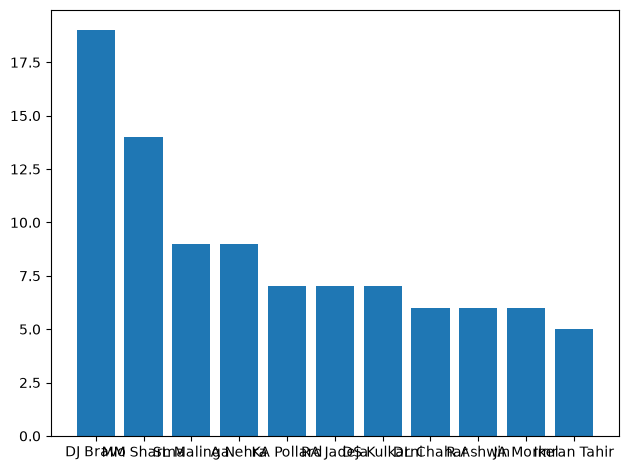

In [36]:
# find wicket fall
inning1['player_dismissed']=inning1['player_dismissed'].fillna('1')
wicket= inning1[inning1['player_dismissed']!='1']
wicket_taken=wicket.groupby('bowler')['player_dismissed'].count().reset_index()
wicket_taken.sort_values('player_dismissed',inplace=True,ascending=False)
wicket_taken=wicket_taken[wicket_taken['player_dismissed']>3]
wicket_taken
plt.bar(wicket_taken['bowler'],wicket_taken['player_dismissed'])
plt.tight_layout()


 # match score till now 

In [37]:
# match score 
match_score= data.groupby(['match_id','inning','batting_team','bowling_team'])['total_runs'].sum().reset_index()
match_score 

,match_id,inning,batting_team,bowling_team,total_runs
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,207
1,1,2,Royal Challengers Bangalore,Sunrisers Hyderabad,172
2,2,1,Mumbai Indians,Rising Pune Supergiant,184
3,2,2,Rising Pune Supergiant,Mumbai Indians,187
4,3,1,Gujarat Lions,Kolkata Knight Riders,183
...,...,...,...,...,...
1523,11413,2,Delhi Capitals,Sunrisers Hyderabad,170
1524,11414,1,Delhi Capitals,Chennai Super Kings,155
1525,11414,2,Chennai Super Kings,Delhi Capitals,162
1526,11415,1,Mumbai Indians,Chennai Super Kings,152


# winnig teams

In [39]:
# winnig teams till now 
winning_teams= match_score.loc[match_score.groupby('match_id')['total_runs'].idxmax()]
winning_teams

,match_id,inning,batting_team,bowling_team,total_runs
0,1,1,Sunrisers Hyderabad,Royal Challengers Bangalore,207
3,2,2,Rising Pune Supergiant,Mumbai Indians,187
5,3,2,Kolkata Knight Riders,Gujarat Lions,184
7,4,2,Kings XI Punjab,Rising Pune Supergiant,164
8,5,1,Royal Challengers Bangalore,Delhi Daredevils,157
...,...,...,...,...,...
1518,11347,1,Kolkata Knight Riders,Mumbai Indians,143
1521,11412,2,Mumbai Indians,Chennai Super Kings,140
1522,11413,1,Sunrisers Hyderabad,Delhi Capitals,171
1525,11414,2,Chennai Super Kings,Delhi Capitals,162


# avg winning score of a team 

TypeError: plot() got an unexpected keyword argument 'x'

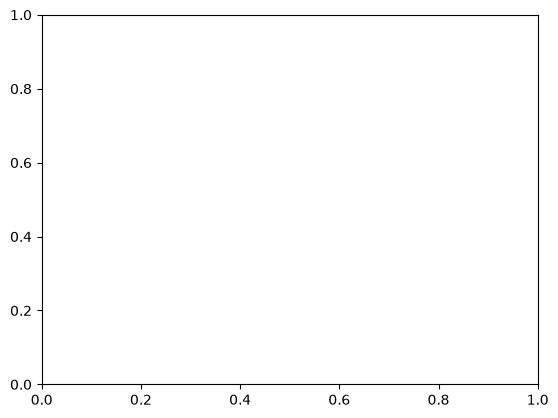

In [63]:
win_avg_score=winning_teams.groupby('batting_team')['total_runs'].mean()
win_avg_score.sort_values(ascending=False)
win_avg_score=pd.DataFrame(win_avg_score).reset_index()
win_avg_score
plt.plot(win_avg_score,x=win_avg_score['batting_team'],y=win_avg_score['total_runs'])